<a href="https://colab.research.google.com/github/CaesarRSingh27/AI-SocietyAssignment/blob/main/S24CSEU2831Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Stress-Testing a Risk Model — COMPAS Recidivism Dataset

**How to use:** (1) set `ROLL_NUMBER` in the first code cell, (2) put `compas-scores-two-years.csv` next to this notebook (or leave it out and the notebook downloads it), (3) *Kernel → Restart & Run All*.
Every number, table and figure used in the PDF is produced here. Tables are saved to `outputs/`, figures to `outputs/*.png`, and the last cell prints a **facts sheet** with the numbers you need for Part 3 and Part 4.

Outcome definitions used throughout
* Model A (OLS): target = `decile_score` (1–10).
* Model B (Logistic): target = `is_recidivist` := `two_year_recid` (1 = re-offended within two years).
* Features (identical for both models): age, priors_count, juv_fel_count, juv_misd_count, juv_other_count, sex_male, charge_felony, race dummies (reference = Caucasian). `decile_score`/`score_text` are **never** used as features (that would leak COMPAS's own output).

In [1]:
import os, json, warnings
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 60)
os.makedirs("outputs", exist_ok=True)

ROLL_NUMBER = "2831"                # your roll number -> last 3 digits "831" = random_state
SEED = int(str(ROLL_NUMBER)[-3:])   # last 3 digits -> random_state
np.random.seed(SEED)
FACTS = {}                          # collects headline numbers for the write-up
print("random_state =", SEED)

random_state = 831


## 0. Data loading and preprocessing

In [2]:
URL = "https://raw.githubusercontent.com/propublica/compas-analysis/master/compas-scores-two-years.csv"
LOCAL = "compas-scores-two-years.csv"
raw = pd.read_csv(LOCAL) if os.path.exists(LOCAL) else pd.read_csv(URL)
print("raw shape:", raw.shape)

raw shape: (7214, 53)


In [3]:
# ---- 0.1 Missing values ---------------------------------------------------
CONT   = ["age", "priors_count", "juv_fel_count", "juv_misd_count", "juv_other_count"]
COUNTS = ["priors_count", "juv_fel_count", "juv_misd_count", "juv_other_count"]
USED = ["sex","age","race","juv_fel_count","juv_misd_count","juv_other_count","priors_count",
        "c_charge_degree","days_b_screening_arrest","is_recid","score_text","decile_score","two_year_recid"]
miss = raw[USED].isna().sum().to_frame("n_missing"); miss["pct_missing"] = 100*miss.n_missing/len(raw)
print(miss[miss.n_missing > 0] if (miss.n_missing > 0).any() else "no missing values in used columns")

n0 = len(raw)
df = raw[USED].dropna()                     # rows missing any used field are dropped (listwise deletion)
n1 = len(df)
# Standard ProPublica data-quality filters (documented in their analysis):
df = df[df.days_b_screening_arrest.between(-30, 30)   # arrest date too far from screening date -> wrong case matched
        & (df.is_recid != -1)                          # no COMPAS case could be found
        & (df.c_charge_degree != "O")                  # ordinary traffic offences
        & (df.score_text != "N/A")]
df = df.reset_index(drop=True)
print(f"rows: raw={n0} -> after dropna={n1} -> after quality filters={len(df)}")
FACTS["data"] = dict(rows_raw=n0, rows_after_dropna=n1, rows_final=len(df),
                     base_rate_recid=float(df.two_year_recid.mean()), mean_decile=float(df.decile_score.mean()))

                         n_missing  pct_missing
days_b_screening_arrest        307     4.255614
rows: raw=7214 -> after dropna=6907 -> after quality filters=6172


In [4]:
# ---- 0.2 Categorical encoding --------------------------------------------
# Collapse tiny race categories (Asian, Native American) into "Other" so the dummies are estimable.
df["race_grp"] = df.race.where(df.race.isin(["African-American","Caucasian","Hispanic"]), "Other")
print(df.race_grp.value_counts())

X_raw = pd.DataFrame(index=df.index)
for c in CONT: X_raw[c] = df[c].astype(float)
X_raw["sex_male"]      = (df.sex == "Male").astype(float)
X_raw["charge_felony"] = (df.c_charge_degree == "F").astype(float)       # F=1, M=0
X_raw["race_AfricanAmerican"] = (df.race_grp == "African-American").astype(float)
X_raw["race_Hispanic"]        = (df.race_grp == "Hispanic").astype(float)
X_raw["race_Other"]           = (df.race_grp == "Other").astype(float)    # reference group: Caucasian
RACE_COLS = ["race_AfricanAmerican","race_Hispanic","race_Other"]
y_dec = df.decile_score.astype(float)        # Model A target
y_bin = df.two_year_recid.astype(int)        # Model B target (is_recidivist)

# ---- train/test split (70/30) with the roll-number seed -------------------
idx_tr, idx_te = train_test_split(df.index, test_size=0.30, random_state=SEED)
print("train:", len(idx_tr), " test:", len(idx_te))

race_grp
African-American    3175
Caucasian           2103
Hispanic             509
Other                385
Name: count, dtype: int64
train: 4320  test: 1852


In [5]:
# ---- 0.3 Outliers -----------------------------------------------------------
tr = X_raw.loc[idx_tr, COUNTS]
q1, q3 = tr.quantile(.25), tr.quantile(.75)
iqr_fence = q3 + 1.5*(q3 - q1)
caps = tr.quantile(.99)
out_tab = pd.DataFrame({"max": X_raw[COUNTS].max(), "IQR_upper_fence": iqr_fence, "p99_cap": caps,
                        "n_above_p99": (X_raw[COUNTS] > caps).sum(), "n_above_IQR_fence": (X_raw[COUNTS] > iqr_fence).sum()})
print(out_tab)
print("age range:", X_raw.age.min(), "-", X_raw.age.max(), "(plausible; not capped)")
# Decision: count variables are heavy right-tailed but real (people do have 30+ priors), so we do NOT delete rows;
# we winsorise at the 99th percentile of the TRAINING data to stop a handful of cases from dominating coefficients.
X_cap = X_raw.copy(); X_cap[COUNTS] = X_cap[COUNTS].clip(upper=caps, axis=1)

# ---- 0.4 Feature scaling -----------------------------------------------------
# Continuous features are z-scored with training-set mean/SD (no test leakage). Dummies stay 0/1.
scaler = StandardScaler().fit(X_cap.loc[idx_tr, CONT])
X_sc = X_cap.copy(); X_sc[CONT] = scaler.transform(X_cap[CONT])
FEATS = list(X_sc.columns)
print("coefficients on continuous features are therefore per +1 SD; dummies per 0->1")
out_tab.to_csv("outputs/preprocessing_outliers.csv"); miss.to_csv("outputs/preprocessing_missing.csv")

                  max  IQR_upper_fence  p99_cap  n_above_p99  n_above_IQR_fence
priors_count     38.0             10.0    22.81           56                492
juv_fel_count    20.0              0.0     2.00           32                208
juv_misd_count   13.0              0.0     2.00           44                352
juv_other_count   9.0              0.0     2.00           50                461
age range: 18.0 - 96.0 (plausible; not capped)
coefficients on continuous features are therefore per +1 SD; dummies per 0->1


## Part 1 — Build: OLS (Model A) vs Logistic (Model B)

Model B (Logit, 0.5 cut)     0    1
Model A (OLS, median cut)          
0                          903   23
1                          273  653

Mismatched: 296 of 1852 = 15.98%
A flags high-risk: 50.0%  (by construction ~50%) | B flags high-risk: 36.5%
Median OLS prediction (decile scale) = 4.484; median logistic P = 0.443; test base rate = 0.451
Accuracy vs actual recidivism: A=0.674  B=0.690
Spearman rank corr (A pred vs B prob): 0.9475
flagged high by A only: 273 | by B only: 23


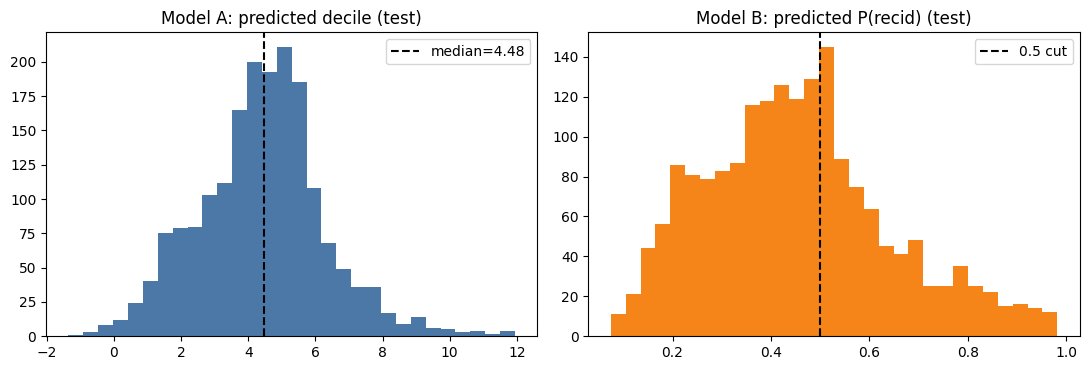

,OLS coef,Logit coef (log-odds),Logit p
const,3.9881,-0.5623,0.0000
age,-1.1357,-0.4696,0.0000
priors_count,1.1956,0.7130,0.0000
juv_fel_count,0.1951,0.0149,0.6906
juv_misd_count,0.1201,0.0298,0.4552
juv_other_count,0.1508,0.1371,0.0002
sex_male,-0.0395,0.3251,0.0002
charge_felony,0.5039,0.2558,0.0003
race_AfricanAmerican,0.4969,-0.0192,0.7995
race_Hispanic,-0.4242,-0.2331,0.0772


In [6]:
addc = lambda X: sm.add_constant(X, has_constant="add")
Xtr, Xte = X_sc.loc[idx_tr], X_sc.loc[idx_te]
ytr_dec, ytr_bin, yte_bin = y_dec.loc[idx_tr], y_bin.loc[idx_tr], y_bin.loc[idx_te]

olsA   = sm.OLS(ytr_dec, addc(Xtr)).fit()
logitB = sm.Logit(ytr_bin, addc(Xtr)).fit(disp=0)
predA  = olsA.predict(addc(Xte))        # continuous predicted decile
pB     = logitB.predict(addc(Xte))      # predicted P(recidivate)

median_A = float(predA.median())
flagA = (predA >= median_A).astype(int)     # high risk if >= median predicted value
flagB = (pB >= 0.5).astype(int)             # high risk if P >= 0.5

cm = pd.crosstab(flagA.rename("Model A (OLS, median cut)"), flagB.rename("Model B (Logit, 0.5 cut)"))
cm = cm.reindex(index=[0,1], columns=[0,1], fill_value=0)
print(cm)
mis = int((flagA != flagB).sum()); mis_pct = 100*mis/len(flagA)
print(f"\nMismatched: {mis} of {len(flagA)} = {mis_pct:.2f}%")
print(f"A flags high-risk: {100*flagA.mean():.1f}%  (by construction ~50%) | B flags high-risk: {100*flagB.mean():.1f}%")
print(f"Median OLS prediction (decile scale) = {median_A:.3f}; median logistic P = {pB.median():.3f}; test base rate = {yte_bin.mean():.3f}")
acc = lambda f: float((f == yte_bin).mean())
print(f"Accuracy vs actual recidivism: A={acc(flagA):.3f}  B={acc(flagB):.3f}")
print("Spearman rank corr (A pred vs B prob):", round(float(pd.Series(predA).corr(pB, method="spearman")), 4))

# Which side of the disagreement is which?
only_A = int(((flagA==1)&(flagB==0)).sum()); only_B = int(((flagA==0)&(flagB==1)).sum())
print(f"flagged high by A only: {only_A} | by B only: {only_B}")
cm.to_csv("outputs/part1_confusion_matrix.csv")
FACTS["Q1"] = dict(median_ols_pred=median_A, median_logit_prob=float(pB.median()), n_test=len(flagA),
    mismatches=mis, mismatch_pct=mis_pct, flagged_high_A_pct=100*flagA.mean(), flagged_high_B_pct=100*flagB.mean(),
    only_A=only_A, only_B=only_B, test_base_rate=float(yte_bin.mean()), acc_A=acc(flagA), acc_B=acc(flagB),
    confusion=cm.values.tolist())

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].hist(predA, bins=30, color="#4C78A8"); ax[0].axvline(median_A, color="k", ls="--", label=f"median={median_A:.2f}")
ax[0].set_title("Model A: predicted decile (test)"); ax[0].legend()
ax[1].hist(pB, bins=30, color="#F58518"); ax[1].axvline(.5, color="k", ls="--", label="0.5 cut")
ax[1].set_title("Model B: predicted P(recid) (test)"); ax[1].legend()
plt.tight_layout(); plt.savefig("outputs/part1_distributions.png", dpi=150); plt.show()
pd.concat([olsA.params.rename("OLS coef"), logitB.params.rename("Logit coef (log-odds)"),
           logitB.pvalues.rename("Logit p")], axis=1).round(4)

**Why do the two rules disagree?** (use your numbers) — (i) A's cut-off is *relative* (median ⇒ ≈50% flagged no matter what), B's is *absolute* (0.5 on a calibrated probability, so the share flagged depends on the base rate); (ii) A models a 1–10 score, B models the actual outcome, so feature weights differ; (iii) the OLS prediction and the logistic probability are non-linearly related (logit link), so the same ordering can still yield different cut-points.

## Part 2.1 — Simpson's-paradox hunt (or a subgroup with a significantly different effect)

In [7]:
def fit_logit(cols, rows=None):
    Xs = X_sc if rows is None else X_sc.loc[rows]
    return sm.Logit(y_bin.loc[Xs.index], addc(Xs[cols])).fit(disp=0)

SPLITS = {
  "sex (Female vs Male)":                  dict(A=X_raw.sex_male==0, B=X_raw.sex_male==1, drop=["sex_male"]),
  "race (African-American vs other)":      dict(A=X_raw.race_AfricanAmerican==1, B=X_raw.race_AfricanAmerican==0, drop=RACE_COLS),
  "age (<=30 vs >30)":                     dict(A=X_raw.age<=30, B=X_raw.age>30, drop=["age"]),
  "charge degree (Felony vs Misdemeanor)": dict(A=X_raw.charge_felony==1, B=X_raw.charge_felony==0, drop=["charge_felony"]),
}
full = fit_logit(FEATS); ciF = full.conf_int()
rows = []
for sname, s in SPLITS.items():
    cols = [c for c in FEATS if c not in s["drop"]]
    mA = fit_logit(cols, X_raw.index[s["A"]]); mB = fit_logit(cols, X_raw.index[s["B"]])
    cA, cB = mA.conf_int(), mB.conf_int()
    for p in cols:
        z = (mA.params[p]-mB.params[p]) / np.sqrt(mA.bse[p]**2 + mB.bse[p]**2)
        pd_ = 2*(1-__import__("scipy.stats", fromlist=["norm"]).norm.cdf(abs(z)))
        sg = np.sign
        rows.append(dict(split=sname, predictor=p, n_A=int(s["A"].sum()), n_B=int(s["B"].sum()),
            b_full=full.params[p], full_lo=ciF.loc[p,0], full_hi=ciF.loc[p,1],
            b_A=mA.params[p], A_lo=cA.loc[p,0], A_hi=cA.loc[p,1], p_A=mA.pvalues[p],
            b_B=mB.params[p], B_lo=cB.loc[p,0], B_hi=cB.loc[p,1], p_B=mB.pvalues[p],
            z_diff=z, p_diff=pd_,
            sign_flip=bool(sg(mA.params[p])!=sg(mB.params[p]) or sg(mA.params[p])!=sg(full.params[p]) or sg(mB.params[p])!=sg(full.params[p]))))
sub = pd.DataFrame(rows)
sub["abs_z"] = sub.z_diff.abs()
sub["sig_diff"] = sub.p_diff < 0.05          # subgroup coefficients differ significantly
cand = sub.sort_values(["sig_diff", "sign_flip", "abs_z"], ascending=False)
cand.to_csv("outputs/part2_1_all_subgroup_comparisons.csv", index=False)
print("Top candidates (significant subgroup difference first, then sign flips, then size of difference):")
print(cand[["split","predictor","b_full","b_A","b_B","sign_flip","z_diff","p_diff","sig_diff"]].head(10).round(4).to_string(index=False))

Top candidates (significant subgroup difference first, then sign flips, then size of difference):
                           split            predictor  b_full     b_A     b_B  sign_flip  z_diff  p_diff  sig_diff
            sex (Female vs Male) race_AfricanAmerican  0.0599 -0.3164  0.1510       True -2.8802  0.0040      True
               age (<=30 vs >30) race_AfricanAmerican  0.0599  0.2761 -0.0105       True  2.2757  0.0229      True
race (African-American vs other)      juv_other_count  0.1219  0.2192  0.0107      False  3.2470  0.0012      True
               age (<=30 vs >30)         priors_count  0.7421  0.9387  0.6594      False  3.1424  0.0017      True
            sex (Female vs Male)         priors_count  0.7421  1.0621  0.7008      False  2.8423  0.0045      True
race (African-American vs other)             sex_male  0.3294  0.5177  0.1222      False  2.7435  0.0061      True
race (African-American vs other)                  age -0.4938 -0.5839 -0.4210      False -2.4764 

In [8]:
# Choose the subgroup/predictor you will write about. Default = top candidate above; override if you prefer another.
CHOSEN_SPLIT, CHOSEN_PRED = None, None      # e.g. "sex (Female vs Male)", "priors_count"
ch = cand.iloc[0] if CHOSEN_SPLIT is None else sub[(sub.split==CHOSEN_SPLIT)&(sub.predictor==CHOSEN_PRED)].iloc[0]
print(f"Chosen: split = {ch.split} | predictor = {ch.predictor}")
print(f"  FULL data  (n={len(X_sc)}): b={ch.b_full:.4f}  95% CI [{ch.full_lo:.4f}, {ch.full_hi:.4f}]  OR={np.exp(ch.b_full):.3f}")
print(f"  Subgroup A (n={ch.n_A}): b={ch.b_A:.4f}  95% CI [{ch.A_lo:.4f}, {ch.A_hi:.4f}]  p={ch.p_A:.4g}  OR={np.exp(ch.b_A):.3f}")
print(f"  Subgroup B (n={ch.n_B}): b={ch.b_B:.4f}  95% CI [{ch.B_lo:.4f}, {ch.B_hi:.4f}]  p={ch.p_B:.4g}  OR={np.exp(ch.b_B):.3f}")
print(f"  Difference A-B: z={ch.z_diff:.3f}, p={ch.p_diff:.4g}; sign reversal: {ch.sign_flip}")
print("  (A, B are listed in the order of the split label, e.g. 'Female vs Male' -> A=Female, B=Male)")
ch.to_frame("value").to_csv("outputs/part2_1_chosen.csv")
FACTS["Q2"] = {k: (v if isinstance(v, (str, bool)) else float(v)) for k, v in ch.items()}

Chosen: split = sex (Female vs Male) | predictor = race_AfricanAmerican
  FULL data  (n=6172): b=0.0599  95% CI [-0.0643, 0.1841]  OR=1.062
  Subgroup A (n=1175): b=-0.3164  95% CI [-0.6027, -0.0300]  p=0.03035  OR=0.729
  Subgroup B (n=4997): b=0.1510  95% CI [0.0126, 0.2895]  p=0.03254  OR=1.163
  Difference A-B: z=-2.880, p=0.003974; sign reversal: True
  (A, B are listed in the order of the split label, e.g. 'Female vs Male' -> A=Female, B=Male)


Interpretation prompts: a reversal/difference usually arises because the subgroup variable is correlated with both the predictor and the outcome (different composition, different baseline risk, different measurement of the predictor). Check, with your own data, how the predictor's distribution differs between A and B (`X_raw.groupby(...)[pred].describe()`), and write about *that* using your coefficients.

In [9]:
s = SPLITS[ch.split]
comp = pd.DataFrame({"A": X_raw.loc[s["A"], ch.predictor].describe(), "B": X_raw.loc[s["B"], ch.predictor].describe()})
base = pd.Series({"A": y_bin[s["A"]].mean(), "B": y_bin[s["B"]].mean()}, name="recid base rate")
print(comp.round(3)); print(base.round(3))

              A         B
count  1175.000  4997.000
mean      0.467     0.526
std       0.499     0.499
min       0.000     0.000
25%       0.000     0.000
50%       0.000     1.000
75%       1.000     1.000
max       1.000     1.000
A    0.351
B    0.479
Name: recid base rate, dtype: float64


## Part 2.2 — Omitted-variable bias

Dropped variable: priors_count (its own coefficient in the full model: 0.7421, p=1.65e-84)
                      coef_full  coef_reduced  p_full  p_reduced  corr_with_dropped  abs_change  pct_change
juv_fel_count            0.0068        0.1259  0.8302     0.0000             0.2289      0.1191   1756.3885
juv_misd_count           0.0188        0.1669  0.5775     0.0000             0.2707      0.1481    788.5657
race_AfricanAmerican     0.0599        0.3064  0.3443     0.0000             0.2202      0.2465    411.2652
charge_felony            0.2207        0.3791  0.0002     0.0000             0.1490      0.1584     71.7997
age                     -0.4938       -0.2992  0.0000     0.0000             0.1177      0.1946     39.4145
juv_other_count          0.1219        0.1679  0.0001     0.0000             0.1203      0.0460     37.7628
sex_male                 0.3294        0.4441  0.0000     0.0000             0.1208      0.1146     34.8015
race_Other              -0.1881       -0.2351

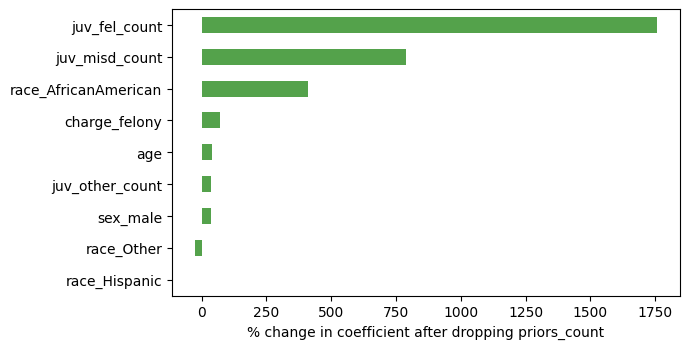

In [10]:
DROP_VAR = "priors_count"       # likely confounder: correlated with race, age AND with recidivism
red_cols = [c for c in FEATS if c != DROP_VAR]
mFull, mRed = fit_logit(FEATS), fit_logit(red_cols)
ovb = pd.DataFrame({"coef_full": mFull.params[red_cols], "coef_reduced": mRed.params[red_cols],
                    "p_full": mFull.pvalues[red_cols], "p_reduced": mRed.pvalues[red_cols],
                    "corr_with_dropped": X_sc[red_cols].corrwith(X_sc[DROP_VAR])})
ovb["abs_change"] = ovb.coef_reduced - ovb.coef_full
ovb["pct_change"] = 100*ovb.abs_change/ovb.coef_full.abs()
ovb = ovb.reindex(ovb["pct_change"].abs().sort_values(ascending=False).index)
print(f"Dropped variable: {DROP_VAR} (its own coefficient in the full model: {mFull.params[DROP_VAR]:.4f}, p={mFull.pvalues[DROP_VAR]:.3g})")
print(ovb.round(4))
ovb.to_csv("outputs/part2_2_omitted_variable.csv")
top = ovb.index[0]
print(f"\nLargest shift: {top} ({ovb.loc[top,'pct_change']:.1f}%)")
print("Caution: % change is unstable when the full-model coefficient is near 0 -> also read the absolute change & CIs.")
FACTS["Q3"] = dict(dropped=DROP_VAR, coef_of_dropped=float(mFull.params[DROP_VAR]), largest_shift=top,
                   table=ovb[["coef_full","coef_reduced","pct_change"]].round(4).to_dict("index"))
ax = ovb["pct_change"].plot.barh(figsize=(7, 3.6), color="#54A24B"); ax.invert_yaxis()
ax.set_xlabel("% change in coefficient after dropping " + DROP_VAR); plt.tight_layout()
plt.savefig("outputs/part2_2_pct_change.png", dpi=150); plt.show()

## Part 2.3 — Adversarial subset (confident but wrong)

In [11]:
rng = np.random.RandomState(SEED)
fp = (pB >= 0.75) & (yte_bin == 0); fn = (pB <= 0.25) & (yte_bin == 1)
n_conf = int(((pB >= 0.75) | (pB <= 0.25)).sum())
pool = pB.index[fp | fn]
print(f"Confident predictions (P>=.75 or P<=.25): {n_conf} of {len(pB)} test rows")
print(f"High-confidence WRONG: {len(pool)} = {100*len(pool)/len(pB):.2f}% of test, "
      f"{100*len(pool)/max(n_conf,1):.2f}% of confident predictions (FP={int(fp.sum())}, FN={int(fn.sum())})")
sample = pool if len(pool) <= 50 else pd.Index(rng.choice(pool, 50, replace=False))
print("rows in adversarial subset:", len(sample))

def profile(ix):
    r = X_raw.loc[ix]; g = df.race_grp.loc[ix]
    return pd.Series({"n": len(ix), "age_mean": r.age.mean(), "age_median": r.age.median(),
        "pct_age<=25": 100*(r.age<=25).mean(), "pct_age>=45": 100*(r.age>=45).mean(), "pct_male": 100*r.sex_male.mean(),
        "pct_AfricanAmerican": 100*(g=="African-American").mean(), "pct_Caucasian": 100*(g=="Caucasian").mean(),
        "pct_Hispanic": 100*(g=="Hispanic").mean(), "pct_Other": 100*(g=="Other").mean(),
        "priors_mean": r.priors_count.mean(), "pct_priors>=5": 100*(r.priors_count>=5).mean(),
        "pct_priors==0": 100*(r.priors_count==0).mean(), "pct_felony": 100*r.charge_felony.mean(),
        "actual_recid_%": 100*y_bin.loc[ix].mean(), "mean_pred_P_%": 100*pB.loc[ix].mean()})
if len(sample) > 0:
    prof = pd.DataFrame({"adversarial": profile(sample), "full_test": profile(idx_te)})
    if fp.sum(): prof["false_pos_only"] = profile(pB.index[fp])
    if fn.sum(): prof["false_neg_only"] = profile(pB.index[fn])
    print(prof.round(2)); prof.to_csv("outputs/part2_3_profile.csv")

    # automatic search for a shared characteristic: single conditions, ranked by over-representation
    T = X_raw.loc[idx_te]; conds = {}
    for c in ["sex_male","charge_felony"] + RACE_COLS:
        conds[f"{c}==1"] = X_raw[c]==1; conds[f"{c}==0"] = X_raw[c]==0
    for c in CONT:
        lo, hi = T[c].quantile(.25), T[c].quantile(.75)
        conds[f"{c}<={lo:g}"] = X_raw[c]<=lo; conds[f"{c}>={hi:g}"] = X_raw[c]>=hi
    conds.update({"priors_count>=5": X_raw.priors_count>=5, "priors_count==0": X_raw.priors_count==0,
                  "age<=25": X_raw.age<=25, "age>=45": X_raw.age>=45})
    tr_ = pd.DataFrame([dict(trait=k, pct_in_subset=100*v.loc[sample].mean(), pct_in_test=100*v.loc[idx_te].mean())
                        for k, v in conds.items()])
    tr_["diff_pp"] = tr_.pct_in_subset - tr_.pct_in_test
    tr_ = tr_.reindex(tr_.diff_pp.abs().sort_values(ascending=False).index)
    print("\nMost over/under-represented traits in the adversarial rows:"); print(tr_.head(10).round(1).to_string(index=False))
    tr_.to_csv("outputs/part2_3_traits.csv", index=False)
    FACTS["Q5"] = dict(n_confident=n_conf, n_wrong=len(pool), pct_wrong_of_test=100*len(pool)/len(pB),
                       n_fp=int(fp.sum()), n_fn=int(fn.sum()), subset_size=len(sample),
                       top_traits=tr_.head(5).round(1).to_dict("records"))
else:
    print("No high-confidence errors exist -> report that; consider also reporting the closest (P>=.65 / P<=.35) as a robustness check.")
    FACTS["Q5"] = dict(n_confident=n_conf, n_wrong=0)
print("\nLogit coefficients (z-scored features) for the failure-mechanism discussion:")
print(logitB.params.round(4).to_string())

Confident predictions (P>=.75 or P<=.25): 442 of 1852 test rows
High-confidence WRONG: 77 = 4.16% of test, 17.42% of confident predictions (FP=27, FN=50)
rows in adversarial subset: 50
                     adversarial  full_test  false_pos_only  false_neg_only
n                          50.00    1852.00           27.00           50.00
age_mean                   45.70      34.62           36.04           51.80
age_median                 49.00      31.00           34.00           51.50
pct_age<=25                 6.00      27.48           14.81            0.00
pct_age>=45                60.00      22.19           22.22           82.00
pct_male                   76.00      81.10           92.59           74.00
pct_AfricanAmerican        54.00      51.13           74.07           42.00
pct_Caucasian              28.00      34.34           22.22           34.00
pct_Hispanic               14.00       8.64            3.70           18.00
pct_Other                   4.00       5.89            

## Part 2.4 — Fairness trade-off sweep (African-American vs Caucasian)

test rows used: 1583 (African-American=947, Caucasian=636)
   t    DP    EO    PP   acc  sel_A  sel_B  TPR_A  TPR_B  FPR_A  FPR_B  PPV_A  PPV_B
0.05 1.000 1.000 1.485 0.471  1.000  1.000  1.000  1.000  1.000  1.000  0.542  0.365
0.15 1.040 1.014 1.448 0.491  0.987  0.950  0.996  0.983  0.977  0.931  0.547  0.377
0.25 1.185 1.035 1.296 0.553  0.928  0.783  0.959  0.927  0.892  0.700  0.560  0.432
0.35 1.371 1.145 1.240 0.617  0.824  0.601  0.908  0.793  0.724  0.490  0.597  0.482
0.45 1.641 1.466 1.327 0.674  0.617  0.376  0.784  0.534  0.419  0.285  0.688  0.519
0.55 2.216 1.726 1.157 0.671  0.373  0.168  0.528  0.306  0.189  0.089  0.768  0.664
0.65 2.542 1.884 1.101 0.634  0.224  0.088  0.341  0.181  0.085  0.035  0.825  0.750
0.75 3.610 2.739 1.127 0.593  0.136  0.038  0.212  0.078  0.046  0.015  0.845  0.750
0.85 3.175 2.172 1.190 0.557  0.055  0.017  0.088  0.034  0.016  0.007  0.865  0.727
0.95   NaN   NaN   NaN 0.534  0.013  0.000  0.019  0.000  0.005  0.000  0.833    NaN


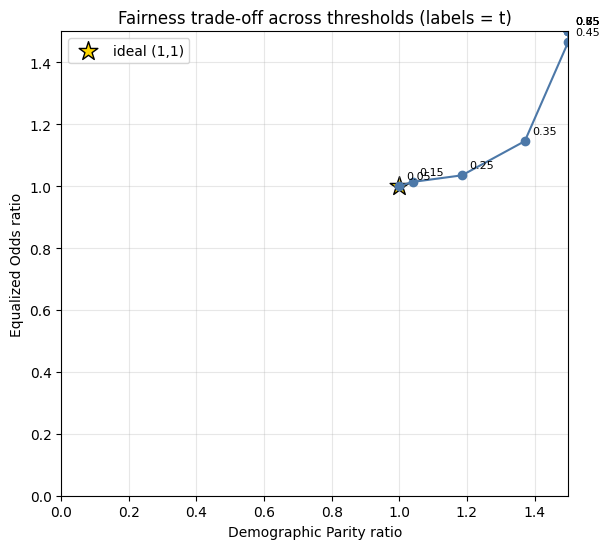

note: points above 1.5 were clipped to the plot border


In [12]:
A_NAME, B_NAME = "African-American", "Caucasian"
grp = df.race_grp.loc[idx_te]; m = grp.isin([A_NAME, B_NAME])
pt, yt, gt = pB[m], yte_bin[m], grp[m]
print(f"test rows used: {m.sum()} ({A_NAME}={int((gt==A_NAME).sum())}, {B_NAME}={int((gt==B_NAME).sum())})")

def sdiv(a, b): return a/b if b > 0 else np.nan
def gstats(y, yh):
    tp = int(((y==1)&(yh==1)).sum()); fn_ = int(((y==1)&(yh==0)).sum())
    fp_ = int(((y==0)&(yh==1)).sum()); tn = int(((y==0)&(yh==0)).sum())
    return dict(sel=(tp+fp_)/len(y), tpr=sdiv(tp, tp+fn_), fpr=sdiv(fp_, fp_+tn), ppv=sdiv(tp, tp+fp_))
res = []
for t in np.round(np.arange(0.05, 0.951, 0.1), 2):
    yh = (pt >= t).astype(int); a = gstats(yt[gt==A_NAME], yh[gt==A_NAME]); b = gstats(yt[gt==B_NAME], yh[gt==B_NAME])
    DP = sdiv(a["sel"], b["sel"]); EO = float(np.minimum(sdiv(a["tpr"], b["tpr"]), sdiv(a["fpr"], b["fpr"]))); PP = sdiv(a["ppv"], b["ppv"])
    res.append(dict(t=t, DP=DP, EO=EO, PP=PP, acc=float((yh==yt).mean()), sel_A=a["sel"], sel_B=b["sel"],
                    TPR_A=a["tpr"], TPR_B=b["tpr"], FPR_A=a["fpr"], FPR_B=b["fpr"], PPV_A=a["ppv"], PPV_B=b["ppv"]))
res = pd.DataFrame(res); res.to_csv("outputs/part2_4_fairness_sweep.csv", index=False)
print(res.round(3).to_string(index=False))

ok = res.dropna(subset=["DP", "EO"])
fig, ax = plt.subplots(figsize=(6.2, 5.6))
ax.plot(ok.DP.clip(upper=1.5), ok.EO.clip(upper=1.5), "-o", color="#4C78A8")
for _, r_ in ok.iterrows(): ax.annotate(f"{r_.t:.2f}", (min(r_.DP, 1.5), min(r_.EO, 1.5)), textcoords="offset points", xytext=(5, 5), fontsize=8)
ax.scatter([1], [1], marker="*", s=200, c="gold", edgecolor="k", label="ideal (1,1)"); ax.legend()
ax.set_xlim(0, 1.5); ax.set_ylim(0, 1.5); ax.set_xlabel("Demographic Parity ratio"); ax.set_ylabel("Equalized Odds ratio")
ax.set_title("Fairness trade-off across thresholds (labels = t)"); ax.grid(alpha=.3); plt.tight_layout()
plt.savefig("outputs/part2_4_tradeoff.png", dpi=150); plt.show()
if (ok[["DP", "EO"]] > 1.5).any().any(): print("note: points above 1.5 were clipped to the plot border")

In [13]:
# ---- quantify the trade-off -------------------------------------------------
gap = lambda v: abs(v - 1)                      # distance from the ideal value 1.0
nd = ok[(ok.sel_A.between(.02, .98)) & (ok.sel_B.between(.02, .98))]   # ignore degenerate "flag everyone/no one" thresholds
def tradeoff(m1, m2):
    d = nd.dropna(subset=[m1, m2]); a = d.loc[(d[m1]-1).abs().idxmin()]; b = d.loc[(d[m2]-1).abs().idxmin()]
    # move from the threshold that is best for m2 to the one that is best for m1; gains/losses in percentage points of distance from 1.0
    Z = 100*(gap(b[m1]) - gap(a[m1])); W = 100*(gap(a[m2]) - gap(b[m2]))
    print(f"{m1} vs {m2}: best-{m1} t={a.t} ({m1}={a[m1]:.3f}, {m2}={a[m2]:.3f}); best-{m2} t={b.t} ({m1}={b[m1]:.3f}, {m2}={b[m2]:.3f})")
    if a.t == b.t: print("   same threshold is best for both -> no trade-off between these two on this sweep"); return dict(Z=np.nan, W=np.nan, cost=np.nan)
    print(f"   moving t={b.t}->{a.t}: {m1} {b[m1]:.3f}->{a[m1]:.3f} (gap to 1.0 shrinks {Z:.1f} pp), {m2} {b[m2]:.3f}->{a[m2]:.3f} (gap grows {W:.1f} pp), cost W/Z = {W/Z if Z > 0 else float('nan'):.2f}")
    return dict(Z=Z, W=W, cost=(W/Z if Z > 0 else np.nan))
TO = {"DP_vs_EO": tradeoff("DP", "EO"), "DP_vs_PP": tradeoff("DP", "PP"), "EO_vs_PP": tradeoff("EO", "PP")}
steps = nd.set_index("t")[["DP", "EO", "PP"]].apply(lambda c: -c.map(gap)).diff().mul(100).round(1).dropna(how="all")
print("\nstep-by-step change in fairness (pp of distance from 1.0; positive = fairer) between consecutive usable thresholds:"); print(steps)
t_dp = nd.loc[(nd.DP-1).abs().idxmin()]; t_eo = nd.loc[(nd.EO-1).abs().idxmin()]; Z = TO["DP_vs_EO"]["Z"]; W = TO["DP_vs_EO"]["W"]
res["composite_gap"] = (res.DP-1).abs() + (res.EO-1).abs() + (res.PP-1).abs()
print("\nthresholds ranked by total distance from (1,1,1):"); print(res.sort_values("composite_gap")[["t","DP","EO","PP","acc","composite_gap"]].round(3).to_string(index=False))
FACTS["Q6_8"] = dict(sweep=res.round(3).to_dict("records"), t_best_DP=float(t_dp.t), t_best_EO=float(t_eo.t), tradeoffs=TO,
                     group_sizes={A_NAME: int((gt==A_NAME).sum()), B_NAME: int((gt==B_NAME).sum())})

DP vs EO: best-DP t=0.25 (DP=1.185, EO=1.035); best-EO t=0.25 (DP=1.185, EO=1.035)
   same threshold is best for both -> no trade-off between these two on this sweep
DP vs PP: best-DP t=0.25 (DP=1.185, PP=1.296); best-PP t=0.65 (DP=2.542, PP=1.101)
   moving t=0.65->0.25: DP 2.542->1.185 (gap to 1.0 shrinks 135.7 pp), PP 1.101->1.296 (gap grows 19.6 pp), cost W/Z = 0.14
EO vs PP: best-EO t=0.25 (EO=1.035, PP=1.296); best-PP t=0.65 (EO=1.884, PP=1.101)
   moving t=0.65->0.25: EO 1.884->1.035 (gap to 1.0 shrinks 84.9 pp), PP 1.101->1.296 (gap grows 19.6 pp), cost W/Z = 0.23

step-by-step change in fairness (pp of distance from 1.0; positive = fairer) between consecutive usable thresholds:
         DP    EO    PP
t                      
0.35  -18.6 -11.0   5.6
0.45  -27.0 -32.1  -8.6
0.55  -57.5 -26.0  17.0
0.65  -32.7 -15.8   5.6
0.75 -106.7 -85.4  -2.6

thresholds ranked by total distance from (1,1,1):
   t    DP    EO    PP   acc  composite_gap
0.05 1.000 1.000 1.485 0.471          0.4

## Facts sheet — numbers for Part 3 and Part 4

In [14]:
for tt in [0.35, 0.45, 0.55]:      # candidate thresholds for Q7 (pick ONE from your own table)
    r_ = res[res.t.round(2) == round(tt, 2)]
    if len(r_): print(r_.round(3).to_string(index=False))
print()
print(json.dumps(FACTS, indent=2, default=lambda o: float(o) if isinstance(o, (np.floating, np.integer)) else str(o)))
json.dump(FACTS, open("outputs/facts.json", "w"), indent=2, default=lambda o: float(o) if isinstance(o, (np.floating, np.integer)) else str(o))

   t    DP    EO   PP   acc  sel_A  sel_B  TPR_A  TPR_B  FPR_A  FPR_B  PPV_A  PPV_B  composite_gap
0.35 1.371 1.145 1.24 0.617  0.824  0.601  0.908  0.793  0.724   0.49  0.597  0.482          0.757
   t    DP    EO    PP   acc  sel_A  sel_B  TPR_A  TPR_B  FPR_A  FPR_B  PPV_A  PPV_B  composite_gap
0.45 1.641 1.466 1.327 0.674  0.617  0.376  0.784  0.534  0.419  0.285  0.688  0.519          1.434
   t    DP    EO    PP   acc  sel_A  sel_B  TPR_A  TPR_B  FPR_A  FPR_B  PPV_A  PPV_B  composite_gap
0.55 2.216 1.726 1.157 0.671  0.373  0.168  0.528  0.306  0.189  0.089  0.768  0.664          2.099

{
  "data": {
    "rows_raw": 7214,
    "rows_after_dropna": 6907,
    "rows_final": 6172,
    "base_rate_recid": 0.4551198963058976,
    "mean_decile": 4.41850291639663
  },
  "Q1": {
    "median_ols_pred": 4.484345741769217,
    "median_logit_prob": 0.4428189834425199,
    "n_test": 1852,
    "mismatches": 296,
    "mismatch_pct": 15.982721382289418,
    "flagged_high_A_pct": 50.0,
    "flagged_h